# Predicción del precio de viviendas en Ames

El objetivo del ejercicio es mejorar la puntuación de **0.18878** obtenida en clase en la competición House Prices de Kaggle. La métrica utilizada es el RMSE entre los logaritmos de los precios; un valor menor indica un error de predicción más reducido.

Se comparan una regresión lineal de referencia, Ridge, Gradient Boosting y una combinación de los dos últimos modelos. La puntuación obtenida en Kaggle es **0.12121**, tras el envío de las predicciones.

## 1. Carga de datos y bibliotecas

El conjunto de entrenamiento contiene 1.460 viviendas con su precio de venta. El conjunto de test incluye 1.459 viviendas cuyo precio debe estimarse.

Para reproducir el análisis, se requieren las bibliotecas recogidas en `requirements.txt` y los archivos oficiales en una carpeta `data/` junto al notebook. También se admite la ubicación habitual de los datos en Kaggle.

Referencias: [competición House Prices](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview) y [documentación de scikit-learn sobre fugas de información](https://scikit-learn.org/stable/common_pitfalls.html).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor, VotingRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_squared_error

# Se fija la semilla para reproducir las divisiones de los datos.
SEED = 42
REFERENCE = 0.18878
# Puntuación externa comunicada tras el envío a Kaggle.
KAGGLE_SCORE = 0.12121
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)
possible_dirs = [Path('data'), Path('../../work/data'),
    Path('/kaggle/input/house-prices-advanced-regression-techniques')]
DATA = next((p for p in possible_dirs if (p/'train.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError('No se encuentran train.csv, test.csv y sample_submission.csv en data/.')
# Se cargan por separado los datos de entrenamiento y de test.
train = pd.read_csv(DATA/'train.csv')
test = pd.read_csv(DATA/'test.csv')
sample = pd.read_csv(DATA/'sample_submission.csv')
assert 'SalePrice' in train and 'SalePrice' not in test
assert train.Id.is_unique and test.Id.is_unique
assert (train.SalePrice > 0).all()
print('Entrenamiento:', train.shape, '| Test:', test.shape)
display(train.head())

Python: 3.12.0 | scikit-learn: 1.5.2
Entrenamiento: (1460, 81) | Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,...,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,...,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,...,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,...,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,...,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Separación y exploración inicial

Se reserva el 20 % del conjunto de entrenamiento para la evaluación final local. El 80 % restante se utiliza para explorar los datos y comparar los modelos mediante validación cruzada. Se fija la semilla en 42 para que la división pueda reproducirse.

La distribución del precio presenta una asimetría hacia valores altos. La transformación `log(SalePrice)` reduce esta asimetría y permite entrenar los modelos en la escala utilizada por la métrica de la competición. Las predicciones se convierten de nuevo a dólares mediante la función exponencial.

El conjunto de test de Kaggle se mantiene separado durante el ajuste del preprocesamiento y la selección del modelo.

Desarrollo: 1168 | Validación final reservada: 292


,Nulos
PoolQC,1162
MiscFeature,1122
Alley,1094
Fence,935
MasVnrType,683
FireplaceQu,547
LotFrontage,217
GarageQual,64
GarageFinish,64
GarageType,64


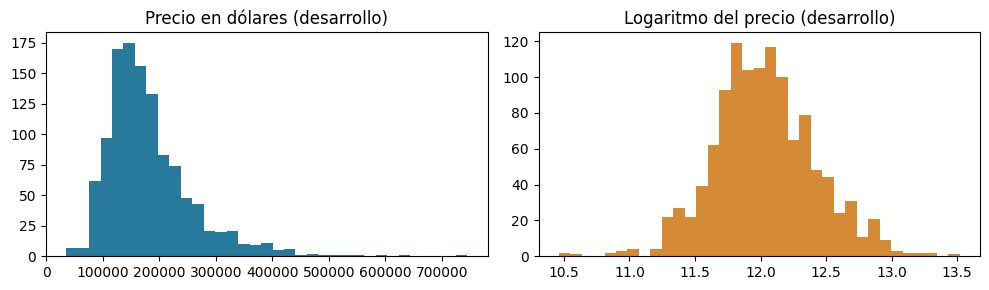

In [2]:
# Se separa el precio de venta de las variables predictoras.
X_raw = train.drop(columns=['Id', 'SalePrice'])
y = train.SalePrice
X_dev_raw, X_hold_raw, y_dev, y_hold = train_test_split(
    X_raw, y, test_size=0.2, random_state=SEED)
print('Desarrollo:', len(y_dev), '| Validación final reservada:', len(y_hold))
display(X_dev_raw.isna().sum().sort_values(ascending=False).head(12).to_frame('Nulos'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(y_dev, bins=35, color='#287a9c')
axes[0].set_title('Precio en dólares (desarrollo)')
axes[1].hist(np.log(y_dev), bins=35, color='#d58b35')
axes[1].set_title('Logaritmo del precio (desarrollo)')
plt.tight_layout()
plt.show()

## 3. Preparación de las variables

Se excluye `Id`, ya que identifica las viviendas. Se conservan las demás variables y se añaden cinco características: superficie total, baños equivalentes, antigüedad de la vivienda, años desde la reforma y superficie total de porches y terrazas. Estas características se calculan mediante reglas fijas, sin utilizar el precio de venta.

La variable `MSSubClass` se trata como categórica, puesto que sus códigos numéricos representan tipos de vivienda. En las superficies y otras magnitudes no negativas se aplica `log1p` para reducir la influencia de valores elevados.

Los valores numéricos ausentes se sustituyen por la mediana. En las variables categóricas se utiliza una etiqueta específica para los valores ausentes. La codificación one-hot permite representar categorías como el barrio sin asignarles un orden artificial.

El preprocesamiento se integra en un `Pipeline`. De este modo, las medianas, las escalas y las categorías se ajustan únicamente con las observaciones de entrenamiento de cada partición. Se mantienen todas las viviendas, incluidos los casos extremos.

In [3]:
def features(df):
    # Se calculan características adicionales a partir de los datos de cada vivienda.
    x = df.copy()
    x['TotalSF'] = x[['TotalBsmtSF', '1stFlrSF', '2ndFlrSF']].sum(axis=1, min_count=3)
    x['TotalBath'] = x.FullBath + .5*x.HalfBath + x.BsmtFullBath + .5*x.BsmtHalfBath
    x['HouseAge'] = (x.YrSold-x.YearBuilt).clip(lower=0)
    x['RemodelAge'] = (x.YrSold-x.YearRemodAdd).clip(lower=0)
    porch = ['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'WoodDeckSF']
    x['TotalPorchSF'] = x[porch].sum(axis=1, min_count=len(porch))
    x['MSSubClass'] = x.MSSubClass.astype(str)
    positive = ['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2',
        'BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF','LowQualFinSF','GrLivArea',
        'GarageArea','WoodDeckSF','OpenPorchSF','EnclosedPorch','3SsnPorch',
        'ScreenPorch','PoolArea','MiscVal','TotalSF','TotalPorchSF']
    x[positive] = np.log1p(x[positive].clip(lower=0))
    return x

def preprocessing(x):
    numeric = x.select_dtypes(include='number').columns.tolist()
    categorical = x.select_dtypes(exclude='number').columns.tolist()
    # Se aplica un tratamiento distinto a las variables numéricas y categóricas.
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())]), numeric),
        ('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical)])

X_dev = features(X_dev_raw)
X_hold = features(X_hold_raw)
X_all = features(X_raw)
X_test = features(test.drop(columns='Id'))
log_y_dev = np.log(y_dev)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

def log_rmse(actual, predicted):
    return float(np.sqrt(mean_squared_error(np.log(actual), np.log(predicted))))

## 4. Comparación de modelos

Se utiliza una validación cruzada de cinco particiones sobre el conjunto de desarrollo. Todos los candidatos se evalúan con las mismas divisiones y se selecciona el que obtiene el menor RMSE logarítmico medio.

Como referencia se emplea una regresión lineal con las diez variables utilizadas en clase. Se incorporan la codificación one-hot y el preprocesamiento por particiones, por lo que esta referencia no reproduce exactamente el procedimiento del notebook original. Sus predicciones se limitan a un mínimo de un dólar para permitir el cálculo del logaritmo.

Se prueban cuatro valores de regularización en Ridge, un modelo Gradient Boosting y una combinación de ambos con pesos iguales. Ridge reduce el efecto de coeficientes elevados, mientras que Gradient Boosting permite representar relaciones no lineales. Los pesos de la combinación se fijan antes de la evaluación.

La media de los errores permite comparar los candidatos. La desviación estándar muestra la variabilidad entre particiones y no constituye un intervalo de confianza. La evaluación final se realiza posteriormente sobre la muestra reservada.

In [4]:
# Se define la referencia lineal con las diez variables utilizadas en clase.
baseline_columns = ['OverallQual','GrLivArea','Neighborhood','YearBuilt',
    'GarageCars','TotalBsmtSF','KitchenQual','FullBath','MSZoning','LotArea']
baseline_x = X_dev_raw[baseline_columns]
baseline = Pipeline([('prepare', preprocessing(baseline_x)), ('model', LinearRegression())])
baseline_errors = []
for fit_idx, val_idx in cv.split(baseline_x):
    fitted = clone(baseline).fit(baseline_x.iloc[fit_idx], y_dev.iloc[fit_idx])
    pred = np.maximum(fitted.predict(baseline_x.iloc[val_idx]), 1)
    baseline_errors.append(log_rmse(y_dev.iloc[val_idx], pred))

gbr = GradientBoostingRegressor(n_estimators=700, learning_rate=0.035,
    max_depth=2, min_samples_leaf=5, loss='huber', random_state=SEED)
estimators = {f'Ridge alpha={a}': Ridge(alpha=a) for a in [5, 15, 40, 100]}
estimators['Gradient Boosting'] = gbr
estimators['Ridge + Gradient Boosting (50/50)'] = VotingRegressor([
    ('ridge', Ridge(alpha=15)), ('boosting', clone(gbr))])
models = {name: Pipeline([('prepare', preprocessing(X_dev)), ('model', estimator)])
    for name, estimator in estimators.items()}
rows = [{'Modelo': 'Referencia lineal (10 variables)',
    'RMSE_log_CV': np.mean(baseline_errors), 'Desviacion_CV': np.std(baseline_errors)}]
# Se evalúan todos los candidatos con las mismas cinco particiones.
for name, model in models.items():
    errors = -cross_val_score(model, X_dev, log_y_dev, cv=cv,
        scoring='neg_root_mean_squared_error', n_jobs=1)
    rows.append({'Modelo': name, 'RMSE_log_CV': errors.mean(), 'Desviacion_CV': errors.std()})
    print(f'{name}: {errors.mean():.5f} ± {errors.std():.5f}', flush=True)
results = pd.DataFrame(rows).sort_values('RMSE_log_CV').reset_index(drop=True)
display(results)
best_name = min(models, key=lambda name: next(r['RMSE_log_CV'] for r in rows if r['Modelo']==name))
print('Modelo elegido por CV:', best_name)
results.to_csv('comparacion_modelos.csv', index=False)

Ridge alpha=5: 0.12668 ± 0.01863
Ridge alpha=15: 0.12445 ± 0.01948
Ridge alpha=40: 0.12456 ± 0.01993
Ridge alpha=100: 0.12672 ± 0.01962
Gradient Boosting: 0.12444 ± 0.01990
Ridge + Gradient Boosting (50/50): 0.11866 ± 0.02040
Modelo elegido por CV: Ridge + Gradient Boosting (50/50)


,Modelo,RMSE_log_CV,Desviacion_CV
0,Ridge + Gradient Boosting (50/50),0.118664,0.020398
1,Gradient Boosting,0.124444,0.019901
2,Ridge alpha=15,0.124451,0.019480
3,Ridge alpha=40,0.124557,0.019931
4,Ridge alpha=5,0.126676,0.018628
5,Ridge alpha=100,0.126723,0.019625
6,Referencia lineal (10 variables),0.294395,0.244924


## 5. Evaluación sobre la muestra reservada

Una vez seleccionado el modelo por validación cruzada, se evalúa sobre el 20 % reservado al inicio. Los parámetros se mantienen sin cambios después de consultar este resultado.

La combinación de Ridge y Gradient Boosting alcanza un RMSE logarítmico local de **0.12754**. La regresión lineal de referencia obtiene **0.16306** sobre esas mismas viviendas. Estos valores permiten comparar ambos modelos en condiciones equivalentes.

La puntuación de Kaggle corresponde a un conjunto distinto y se registra por separado. El gráfico permite observar la relación entre los precios reales y las predicciones en la validación local.

Referencia adaptada, validación local: 0.16306
Modelo seleccionado, validación local: 0.12754
Objetivo de Kaggle (conjunto distinto): 0.18878
Puntuación en Kaggle (resultado externo comunicado): 0.12121


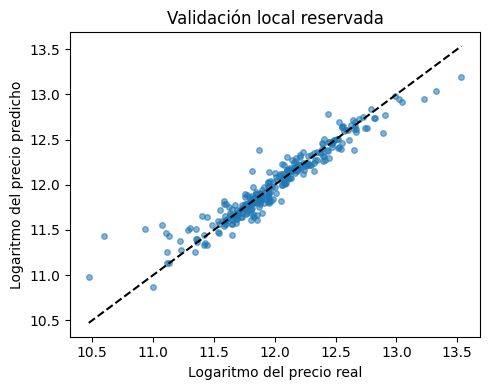

In [5]:
# Se evalúa el modelo elegido sobre la muestra reservada.
selected = clone(models[best_name]).fit(X_dev, log_y_dev)
hold_pred = np.exp(selected.predict(X_hold))
hold_score = log_rmse(y_hold, hold_pred)
baseline_final = clone(baseline).fit(baseline_x, y_dev)
baseline_hold_pred = np.maximum(baseline_final.predict(X_hold_raw[baseline_columns]), 1)
baseline_hold_score = log_rmse(y_hold, baseline_hold_pred)
print(f'Referencia adaptada, validación local: {baseline_hold_score:.5f}')
print(f'Modelo seleccionado, validación local: {hold_score:.5f}')
print(f'Objetivo de Kaggle (conjunto distinto): {REFERENCE:.5f}')
print(f'Puntuación en Kaggle (resultado externo comunicado): {KAGGLE_SCORE:.5f}')
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(np.log(y_hold), np.log(hold_pred), alpha=.55, s=16)
limits = [min(np.log(y_hold).min(), np.log(hold_pred).min()),
    max(np.log(y_hold).max(), np.log(hold_pred).max())]
ax.plot(limits, limits, '--', color='black')
ax.set(xlabel='Logaritmo del precio real', ylabel='Logaritmo del precio predicho',
    title='Validación local reservada')
plt.tight_layout()
plt.show()

## 6. Entrenamiento final y generación de predicciones

Tras completar la evaluación, se ajusta el modelo seleccionado con las 1.460 viviendas del conjunto de entrenamiento. A continuación, se estiman los precios de las 1.459 viviendas del conjunto de test.

Antes de guardar `submission.csv`, se comprueba que las columnas sean `Id` y `SalePrice`, que los identificadores coincidan con el archivo de ejemplo y que todas las predicciones sean positivas y finitas.

In [6]:
# Se ajusta el modelo final con todas las viviendas cuyo precio se conoce.
final_model = clone(models[best_name]).fit(X_all, np.log(y))
test_pred = np.exp(final_model.predict(X_test))
submission = pd.DataFrame({'Id': test.Id, 'SalePrice': test_pred})
# Se verifica el formato exigido para el envío de predicciones.
assert list(submission.columns) == ['Id', 'SalePrice']
assert len(submission) == len(test) == len(sample)
assert submission.Id.tolist() == sample.Id.tolist()
assert submission.Id.is_unique
assert np.isfinite(submission.SalePrice).all() and (submission.SalePrice > 0).all()
submission.to_csv('submission.csv', index=False)
summary = {'modelo': best_name, 'rmse_log_validacion_local': hold_score,
    'rmse_log_referencia_local': baseline_hold_score, 'objetivo_kaggle': REFERENCE,
    'puntuacion_oficial_kaggle': KAGGLE_SCORE,
    'fuente_puntuacion_kaggle': 'Resultado comunicado por el alumno; captura pendiente de adjuntar a la PR', 'filas_submission': len(submission), 'semilla': SEED}
Path('resultados.json').write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding='utf-8')
display(submission.head())
print('Archivo generado: submission.csv | Filas:', len(submission))

Archivo generado: submission.csv | Filas: 1459


,Id,SalePrice
0,1461,119836.307487
1,1462,161341.284214
2,1463,185736.607375
3,1464,193570.179624
4,1465,195106.790122


## 7. Resultados y conclusiones

La combinación de Ridge y Gradient Boosting con pesos iguales obtiene el menor error medio en la validación cruzada, con un valor aproximado de **0.11866**. En la muestra reservada, el error es **0.12754**, frente a **0.16306** de la referencia lineal adaptada.

Tras el envío de las predicciones, se ha obtenido una puntuación de **0.12121** en Kaggle. Este resultado mejora la referencia de clase de **0.18878**, con una reducción del error de aproximadamente el **35.79 %**. La puntuación de la plataforma se incorpora como un resultado externo; no se calcula a partir de los precios del test en este notebook.

El uso de más variables, la transformación logarítmica del precio y la combinación de modelos permiten mejorar la predicción respecto a la referencia local. El preprocesamiento por particiones evita utilizar información de validación durante el ajuste.

### Limitaciones

La evaluación local depende de la muestra y de la semilla utilizadas. Se conservan los casos extremos, que pueden influir en el error. Los resultados obtenidos no garantizan el mismo rendimiento sobre viviendas ajenas a los conjuntos analizados.